In [21]:
from langchain_community.document_loaders import TextLoader, DirectoryLoader
from langchain_openai import OpenAIEmbeddings, ChatOpenAI 
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.documents import Document 
from langchain_text_splitters import RecursiveCharacterTextSplitter 
from langchain_chroma import Chroma 
from pathlib import Path 
from dotenv import load_dotenv 

In [9]:
# 1. Load the api keys 

load_dotenv() 

True

In [10]:
# 2. Create the LLM and Embedding model 

llm = ChatOpenAI(model = 'gpt-5-mini')
embedder = OpenAIEmbeddings(model = 'text-embedding-3-small', 
                            dimensions= 1024) # defaul 1536 

In [11]:
# 3. Load the documents from source 

loader = DirectoryLoader(path = Path("./cleaned-transcripts/").as_posix(), 
                         loader_cls= TextLoader, 
                         show_progress= True )


docs = loader.load()

100%|██████████| 3/3 [00:00<00:00, 362.98it/s]


In [12]:
docs[1].page_content[:1000]

"WEBVTT\nYeah, am I audible now?\nYes, great, great.\nOkay guys, 5 minutes, we'll wait for everyone to join and then we'll start.\nOkay, one thing I'm working on a new system.\nEverything is clearly visible to you.\nIs my screen share visible?\nAm I audible? Everything is perfect?\nI'll discuss everything. I'll discuss the prerequisites.\nEverything. Don't worry about it.\nGreat, great, great.\nSo, we'll do one thing.\nLike starting in 15-20 minutes, we'll have a little discussion.\nOkay, I'll discuss my audience.\nHow is my audience?\nBecause when I was designing the curriculum for the course,\nI was not sure what kind of audience is coming to me.\nWhat is your prior experience?\nSo we'll discuss that a little bit and then we'll start.\nOkay, don't worry about it.\nEverything will depend on your feedback.\nYeah.\nHow many classes will there be?\nNow we are planning to have around 20 classes.\nOkay, the rest will depend on how many sessions you are able to understand.\nAgain, based on 

In [14]:
# 4. Chunk the text 

chunker = RecursiveCharacterTextSplitter(chunk_size = 500, 
                                         chunk_overlap = 50)


chunks = chunker.split_documents(docs)


In [15]:
print(f"Chunks: {len(chunks)}")

Chunks: 577


In [18]:
# 5. Create a vector store 

vs = Chroma(
    collection_name = 'rag_demo', 
    embedding_function= embedder, 
    persist_directory= Path("./saved-embeddings").as_posix() 
)

# 6. add documents 

vs.add_documents(chunks)

['5b322fcc-ddd1-448b-9b9e-8f421a64c30c',
 '90cef088-3c50-4ba0-9203-07a19a7f0cbb',
 'f2187f00-f183-4e82-a49f-5d308f1279b6',
 '0a4078dd-4c6d-4206-af4a-4507bc4c0ff5',
 '3a97cc40-5ae0-43ac-9a81-ac5effa1f7d9',
 '1db610da-e201-4fe8-8498-ee2d412ce67b',
 'f37d4531-7758-4fd7-90ad-7e3fcfafa1c3',
 '5e5bc134-b5e6-45c2-b431-6f542481a68e',
 '4fb77dd7-5eba-4754-9837-42202d5f18f6',
 'bc1ba3ce-d47a-469f-9778-5ab85486f8b3',
 '6bf653b2-397c-4ab7-82c6-5e2a3416ca6d',
 'd27c0c82-5982-462f-924f-afd581ad7853',
 '475fc42e-6560-43d8-9059-6620f8b6e202',
 '304532f1-038e-4f98-8e01-27baf5d27379',
 '985c9dfe-0a0e-4315-a442-48926cc516ca',
 '39ac756c-c258-40c9-b16e-f3eabdae5c5a',
 '20e072a2-e98c-47d7-89dd-10b1a907d85e',
 '5e5acb94-c419-4f00-8229-018fff16e6bd',
 '6ef9d932-f8ed-4000-838c-7a455b1b8b3c',
 'bb53294b-db14-4660-868a-0dea5266b5e3',
 'bfb951a0-2f6c-4dd7-895c-f0c735b0f27d',
 '96dff1ba-73c2-435b-a2a6-c3ae4d70d746',
 '213e41ca-50a9-4110-bb73-b9c9c02c4bb6',
 '4287a66a-2056-4ae0-a3ce-b54c76ab404b',
 '6cc90887-d451-

In [19]:
# 7. Retriever 

retriever = vs.as_retriever(search_kwargs = {"k": 3})

In [20]:
# creating langgraph 
from langgraph.graph import StateGraph , START, END 
from typing import TypedDict, Literal

In [22]:
# 8. Creating langgraph graph 

class RagState(TypedDict): 
    query: str 
    retrieved_docs : list[Document]
    context: str 
    prompt: ChatPromptTemplate
    response: str 

In [23]:
def retrieve(state: RagState) -> dict: 
    query = state['query']
    retrieved_docs = retriever.invoke(query)


    context = "\n\n".join([doc.page_content for doc in retrieved_docs])

    return {"retrieved_context": retrieved_docs, 
            "context": context}

In [27]:
def augmentation(state: RagState) -> dict: 
    # query = state['query']
    # context = state['context']

    prompt = ChatPromptTemplate.from_messages([
        ("system", """ You are helpful assistant. Answer the user query 
                        based on the given context only. If you do not know the answer 
                        say I don't know. Do not add any preamble to the response"""), 
        ("human", "context: {context}\n\nquery: {query}")
    ])

    return {"prompt": prompt}

In [30]:
from langchain_core.output_parsers import StrOutputParser

In [32]:
def generation(state: RagState)-> dict: 

    query = state['query']
    context = state['context']
    prompt = state['prompt']

    rag_chain = prompt | llm | StrOutputParser()

    response = rag_chain.invoke({"context": context, 
                                 "query": query})

    return {"response": response}

In [33]:
graph_builder = StateGraph(RagState) 

graph_builder.add_node("retrieve", retrieve)
graph_builder.add_node("augmentation", augmentation)
graph_builder.add_node("generation", generation)


graph_builder.add_edge(START, "retrieve")
graph_builder.add_edge("retrieve", "augmentation")
graph_builder.add_edge("augmentation", "generation")
graph_builder.add_edge("generation", END)


In [34]:
workflow = graph_builder.compile()

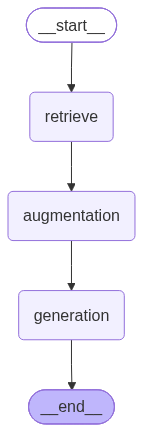

In [35]:
workflow

In [41]:
initial_state = {"query": input("Ask your question here: ")}
final_state = workflow.invoke(initial_state)
print(final_state['response'])

- Two main prerequisites: LangChain and LangGraph (basic understanding only).  
- Study source: the course YouTube playlist — just the basics, no need for advanced concepts.  
- For LangGraph you don’t need deep knowledge of concepts like memory.  
- If you’ve never deployed models, the course will start from the very basics, so deployment experience isn’t required.


'The discussion is about LLMEvals/DeepEval — LLM evaluation and LLM Ops (with mentions of Ragaas and Constitutional AI).'